In [1]:
import glob, os, sys
import pandas as pd
import torch

# Trouve automatiquement le dossier de ton dataset (pas besoin de connaître le chemin exact)
DOSSIER = os.path.dirname(glob.glob("/kaggle/input/**/train.csv", recursive=True)[0])
print("Dossier des données :", DOSSIER)
print("Fichiers :", os.listdir(DOSSIER))

sys.path.append(DOSSIER)  # pour pouvoir importer ton metrics.py
from metrics import GROUPES, evaluer, rapport_par_groupe, probas_vers_predictions, chercher_seuils

train = pd.read_csv(f"{DOSSIER}/train.csv", dtype={"id": str})
val = pd.read_csv(f"{DOSSIER}/val.csv", dtype={"id": str})
print("Train :", train.shape, "| Validation :", val.shape)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device :", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "PAS DE GPU !")

Dossier des données : /kaggle/input/datasets/<compte>/arxiv-multilabel-donnees
Fichiers : ['metrics.py', 'test.csv', 'train.csv', 'val.csv']
Train : (12132, 11) | Validation : (2609, 11)
Device : cuda | Tesla T4


In [2]:
import re
from collections import Counter

def tokeniser(texte):
    """'Deep Neural-Networks for X' -> ['deep', 'neural', 'networks', 'for', 'x']"""
    return re.findall(r"[a-z0-9]+", texte.lower())

# Compte chaque mot du TRAIN (jamais de la validation : sinon, fuite de données)
compteur = Counter()
for texte in train["text"]:
    compteur.update(tokeniser(texte))

# On garde les mots vus au moins 2 fois (les autres sont trop rares pour être appris)
vocab = {"<pad>": 0, "<unk>": 1}
for mot, n in compteur.items():
    if n >= 2:
        vocab[mot] = len(vocab)

print("Mots différents dans le train :", len(compteur))
print("Taille du vocabulaire          :", len(vocab))
print("Exemple :", tokeniser(train["text"].iloc[0])[:12])

Mots différents dans le train : 43596
Taille du vocabulaire          : 27260
Exemple : ['in', 'this', 'note', 'we', 'develop', 'tools', 'and', 'techniques', 'for', 'the', 'treatment', 'of']


In [3]:
from torch.utils.data import Dataset, DataLoader

MAX_LEN = 300  # nombre maximum de mots lus par résumé

def encoder(texte):
    """texte -> liste de numéros (1 = mot inconnu), coupée à MAX_LEN"""
    numeros = [vocab.get(mot, 1) for mot in tokeniser(texte)]
    return numeros[:MAX_LEN]

class ArxivDataset(Dataset):
    def __init__(self, df):
        self.ids, self.longueurs = [], []
        for texte in df["text"]:
            numeros = encoder(texte)
            self.longueurs.append(len(numeros))                         # vraie longueur (sans padding)
            self.ids.append(numeros + [0] * (MAX_LEN - len(numeros)))   # complète avec <pad> = 0
        self.ids = torch.tensor(self.ids)
        self.longueurs = torch.tensor(self.longueurs)
        self.labels = torch.tensor(df[GROUPES].values, dtype=torch.float32)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return self.ids[i], self.longueurs[i], self.labels[i]

ds_train = ArxivDataset(train)
ds_val = ArxivDataset(val)
dl_train = DataLoader(ds_train, batch_size=64, shuffle=True)  # mélangé à chaque epoch
dl_val = DataLoader(ds_val, batch_size=256)                   # pas besoin de mélanger

# On regarde un paquet
ids, longueurs, labels = next(iter(dl_train))
print("ids       :", ids.shape)
print("longueurs :", longueurs[:5].tolist())
print("labels    :", labels.shape)
coupes = (ds_train.longueurs == MAX_LEN).float().mean().item()
print(f"Résumés coupés à {MAX_LEN} mots : {100 * coupes:.2f} %")

ids       : torch.Size([64, 300])
longueurs : [108, 160, 191, 126, 206]
labels    : torch.Size([64, 8])
Résumés coupés à 300 mots : 0.61 %


In [4]:
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

class BiLSTM(nn.Module):
    def __init__(self, taille_vocab, dim_emb=200, dim_cachee=128, nb_classes=8, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(taille_vocab, dim_emb, padding_idx=0)
        self.lstm = nn.LSTM(dim_emb, dim_cachee, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(dropout)
        self.sortie = nn.Linear(2 * dim_cachee, nb_classes)

    def forward(self, ids, longueurs):
        x = self.dropout(self.embedding(ids))                       # (batch, 300, 200)
        # "pack" : indique au LSTM la vraie longueur de chaque résumé -> il ignore le padding
        x = pack_padded_sequence(x, longueurs.cpu(), batch_first=True, enforce_sorted=False)
        h, _ = self.lstm(x)
        h, _ = pad_packed_sequence(h, batch_first=True, total_length=ids.size(1))  # (batch, 300, 256)
        masque = (ids != 0).unsqueeze(-1)                            # True = vrai mot, False = padding
        h = h.masked_fill(~masque, -1e9)                             # le padding ne peut pas "gagner" le max
        h = h.max(dim=1).values                                      # (batch, 256)
        return self.sortie(self.dropout(h))                          # (batch, 8) : un score par groupe

modele = BiLSTM(len(vocab)).to(device)  # .to(device) = on envoie le modèle sur le GPU
print("Nombre de paramètres :", sum(p.numel() for p in modele.parameters()))

# Test : un paquet traverse le modèle
with torch.no_grad():
    scores = modele(ids.to(device), longueurs)
print("Sortie :", scores.shape)

Nombre de paramètres : 5791976
Sortie : torch.Size([64, 8])


In [5]:
import copy

torch.manual_seed(42)                              # résultats reproductibles
modele = BiLSTM(len(vocab)).to(device)             # modèle neuf : on repart de zéro
optimiseur = torch.optim.Adam(modele.parameters(), lr=1e-3)
fonction_perte = nn.BCEWithLogitsLoss()


def predire(modele, dl):
    """Renvoie les probabilités (n, 8) et les vrais labels (n, 8) pour tout un DataLoader."""
    modele.eval()                                  # mode évaluation : dropout désactivé
    toutes_probas, tous_labels = [], []
    with torch.no_grad():                          # pas de gradients : plus rapide
        for ids, longueurs, labels in dl:
            scores = modele(ids.to(device), longueurs)
            toutes_probas.append(torch.sigmoid(scores).cpu())  # sigmoïde : scores -> probabilités
            tous_labels.append(labels)
    return torch.cat(toutes_probas).numpy(), torch.cat(tous_labels).numpy()


NB_EPOCHS_MAX = 20
PATIENCE = 3                                       # arrêt si pas de progrès pendant 3 epochs
meilleur_f1, meilleur_etat, epochs_sans_progres = 0, None, 0
historique = []

for epoch in range(1, NB_EPOCHS_MAX + 1):
    # --- 1. Entraînement : un passage complet sur le train ---
    modele.train()                                 # mode entraînement : dropout actif
    perte_totale = 0
    for ids, longueurs, labels in dl_train:
        ids, labels = ids.to(device), labels.to(device)
        optimiseur.zero_grad()                     # efface les corrections du paquet précédent
        scores = modele(ids, longueurs)            # geste 1 : prédire
        perte = fonction_perte(scores, labels)     # geste 2 : mesurer l'erreur
        perte.backward()                           # geste 3 : calculer les corrections
        optimiseur.step()                          # geste 4 : corriger
        perte_totale += perte.item() * len(labels)
    perte_moyenne = perte_totale / len(ds_train)

    # --- 2. Note sur la validation (seuil 0.5) ---
    probas_val, y_val = predire(modele, dl_val)
    f1_val = evaluer(y_val, probas_vers_predictions(probas_val))["micro_f1"]
    historique.append({"epoch": epoch, "perte_train": perte_moyenne, "micro_f1_val": f1_val})
    print(f"Epoch {epoch:2d} | perte train {perte_moyenne:.4f} | micro-F1 val {f1_val:.4f}")

    # --- 3. Early stopping : on garde la meilleure version ---
    if f1_val > meilleur_f1:
        meilleur_f1 = f1_val
        meilleur_etat = copy.deepcopy(modele.state_dict())  # copie des paramètres
        epochs_sans_progres = 0
    else:
        epochs_sans_progres += 1
        if epochs_sans_progres >= PATIENCE:
            print(f"Arrêt anticipé : pas de progrès depuis {PATIENCE} epochs")
            break

modele.load_state_dict(meilleur_etat)              # on recharge la meilleure version
print("Meilleur micro-F1 validation (seuil 0.5) :", round(meilleur_f1, 4))

Epoch  1 | perte train 0.4815 | micro-F1 val 0.2790
Epoch  2 | perte train 0.4069 | micro-F1 val 0.5081
Epoch  3 | perte train 0.3416 | micro-F1 val 0.6145
Epoch  4 | perte train 0.2971 | micro-F1 val 0.6910
Epoch  5 | perte train 0.2674 | micro-F1 val 0.7051
Epoch  6 | perte train 0.2466 | micro-F1 val 0.7240
Epoch  7 | perte train 0.2258 | micro-F1 val 0.7293
Epoch  8 | perte train 0.2104 | micro-F1 val 0.7282
Epoch  9 | perte train 0.1974 | micro-F1 val 0.7438
Epoch 10 | perte train 0.1864 | micro-F1 val 0.7492
Epoch 11 | perte train 0.1747 | micro-F1 val 0.7572
Epoch 12 | perte train 0.1631 | micro-F1 val 0.7447
Epoch 13 | perte train 0.1569 | micro-F1 val 0.7524
Epoch 14 | perte train 0.1466 | micro-F1 val 0.7478
Arrêt anticipé : pas de progrès depuis 3 epochs
Meilleur micro-F1 validation (seuil 0.5) : 0.7572


In [6]:
import copy

def entrainer(nom, dropout=0.3, dim_cachee=128, lr=1e-3, weight_decay=0.0, embeddings=None,
              nb_epochs_max=20, patience=3):
    """Entraîne un BiLSTM avec ces réglages et renvoie le meilleur modèle + ses scores."""
    torch.manual_seed(42)
    modele = BiLSTM(len(vocab), dim_cachee=dim_cachee, dropout=dropout).to(device)
    if embeddings is not None:
        modele.embedding.weight.data.copy_(embeddings)
    optimiseur = torch.optim.Adam(modele.parameters(), lr=lr, weight_decay=weight_decay)
    fonction_perte = nn.BCEWithLogitsLoss()

    meilleur_f1, meilleur_etat, sans_progres, historique = 0, None, 0, []
    for epoch in range(1, nb_epochs_max + 1):
        modele.train()
        perte_totale = 0
        for ids, longueurs, labels in dl_train:
            ids, labels = ids.to(device), labels.to(device)
            optimiseur.zero_grad()
            perte = fonction_perte(modele(ids, longueurs), labels)
            perte.backward()
            optimiseur.step()
            perte_totale += perte.item() * len(labels)
        probas_val, y_val = predire(modele, dl_val)
        f1_val = evaluer(y_val, probas_vers_predictions(probas_val))["micro_f1"]
        historique.append({"epoch": epoch, "perte_train": perte_totale / len(ds_train),
                           "micro_f1_val": f1_val})
        if f1_val > meilleur_f1:
            meilleur_f1, meilleur_etat, sans_progres = f1_val, copy.deepcopy(modele.state_dict()), 0
        else:
            sans_progres += 1
            if sans_progres >= patience:
                break

    modele.load_state_dict(meilleur_etat)
    probas_val, y_val = predire(modele, dl_val)
    seuils = chercher_seuils(y_val, probas_val)
    scores = evaluer(y_val, probas_vers_predictions(probas_val, seuils))
    meilleure_epoch = max(historique, key=lambda h: h["micro_f1_val"])["epoch"]

    print(f"{nom:24s} | epoch {meilleure_epoch:2d} | micro-F1 (0.5) {meilleur_f1:.4f} "
          f"| avec seuils : micro {scores['micro_f1']:.4f}  macro {scores['macro_f1']:.4f}")
    resultat = {"nom": nom, "dropout": dropout, "dim_cachee": dim_cachee, "lr": lr,
                "weight_decay": weight_decay, "glove": embeddings is not None,
                "meilleure_epoch": meilleure_epoch, "micro_f1_05": meilleur_f1,
                "micro_f1_seuils": scores["micro_f1"], "macro_f1_seuils": scores["macro_f1"]}
    return modele, resultat, historique, seuils

In [7]:
experiences = []

_, res, _, _ = entrainer("1. départ")
experiences.append(res)

_, res, _, _ = entrainer("2. dropout 0.5", dropout=0.5)
experiences.append(res)

pd.DataFrame(experiences)[["nom", "meilleure_epoch", "micro_f1_05", "micro_f1_seuils", "macro_f1_seuils"]]

1. départ                | epoch 11 | micro-F1 (0.5) 0.7572 | avec seuils : micro 0.7628  macro 0.7557
2. dropout 0.5           | epoch 20 | micro-F1 (0.5) 0.7456 | avec seuils : micro 0.7581  macro 0.7502


,nom,meilleure_epoch,micro_f1_05,micro_f1_seuils,macro_f1_seuils
0,1. départ,11,0.757155,0.762812,0.755727
1,2. dropout 0.5,20,0.745575,0.758100,0.750206


In [8]:
import numpy as np

# 1. Trouver le fichier GloVe de dimension 200 (la même taille que notre embedding)
tous = glob.glob("/kaggle/input/**/glove*.txt", recursive=True)
print("Fichiers GloVe disponibles :", tous)
chemin_glove = [f for f in tous if "200d" in f][0]
print("On utilise :", chemin_glove)

# 2. Préparer un tableau : une ligne de 200 nombres par mot de NOTRE vocabulaire
matrice = np.random.normal(0, 0.3, (len(vocab), 200)).astype("float32")
matrice[0] = 0  # <pad> = vecteur nul

# 3. Recopier le vecteur GloVe de chaque mot qui existe aussi dans notre vocabulaire
trouves = 0
with open(chemin_glove, encoding="utf-8") as f:
    for ligne in f:
        morceaux = ligne.rstrip().split(" ")
        mot = morceaux[0]
        if mot in vocab:
            matrice[vocab[mot]] = np.array(morceaux[1:], dtype="float32")
            trouves += 1

print(f"Mots trouvés dans GloVe : {trouves} / {len(vocab)} ({100 * trouves / len(vocab):.1f} %)")
embeddings_glove = torch.tensor(matrice)

Fichiers GloVe disponibles : ['/kaggle/input/datasets/<compte>/glove-global-vectors-for-word-representation/glove.6B.100d.txt', '/kaggle/input/datasets/<compte>/glove-global-vectors-for-word-representation/glove.6B.200d.txt', '/kaggle/input/datasets/<compte>/glove-global-vectors-for-word-representation/glove.6B.50d.txt']
On utilise : /kaggle/input/datasets/<compte>/glove-global-vectors-for-word-representation/glove.6B.200d.txt
Mots trouvés dans GloVe : 22597 / 27260 (82.9 %)


In [9]:
_, res, _, _ = entrainer("3. GloVe", embeddings=embeddings_glove)
experiences.append(res)

pd.DataFrame(experiences)[["nom", "meilleure_epoch", "micro_f1_05", "micro_f1_seuils", "macro_f1_seuils"]]

3. GloVe                 | epoch  8 | micro-F1 (0.5) 0.7767 | avec seuils : micro 0.7856  macro 0.7786


,nom,meilleure_epoch,micro_f1_05,micro_f1_seuils,macro_f1_seuils
0,1. départ,11,0.757155,0.762812,0.755727
1,2. dropout 0.5,20,0.745575,0.758100,0.750206
2,3. GloVe,8,0.776699,0.785608,0.778639


BiLSTM final (GloVe)     | epoch  8 | micro-F1 (0.5) 0.7767 | avec seuils : micro 0.7856  macro 0.7786


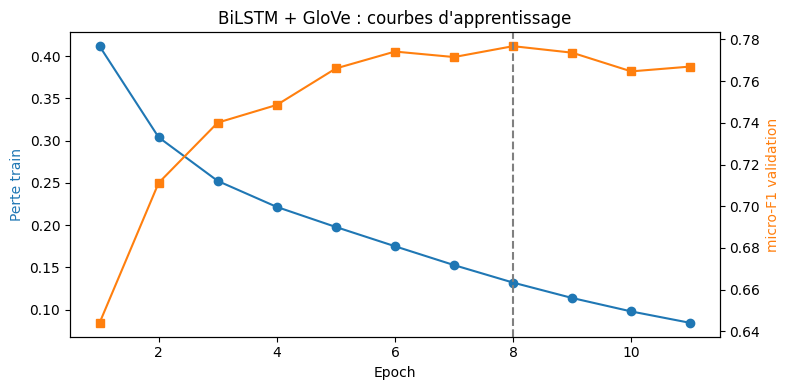

Fichiers sauvegardés dans /kaggle/working


In [10]:
import json
import matplotlib.pyplot as plt

# 1. Réentraîner la meilleure configuration pour récupérer le modèle
modele_final, res_final, historique_final, seuils_final = entrainer("BiLSTM final (GloVe)",
                                                                    embeddings=embeddings_glove)

# 2. Sauvegarder : modèle, vocabulaire, seuils, historique et journal des expériences
torch.save(modele_final.state_dict(), "/kaggle/working/bilstm.pt")
with open("/kaggle/working/bilstm_vocab.json", "w") as f:
    json.dump(vocab, f)
with open("/kaggle/working/bilstm_val.json", "w") as f:
    json.dump({"modele_final": res_final, "seuils": seuils_final.tolist(),
               "historique": historique_final, "experiences": experiences}, f, indent=2)

# 3. Courbes d'apprentissage
hist = pd.DataFrame(historique_final)
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(hist["epoch"], hist["perte_train"], "o-", color="tab:blue")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Perte train", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(hist["epoch"], hist["micro_f1_val"], "s-", color="tab:orange")
ax2.set_ylabel("micro-F1 validation", color="tab:orange")
ax2.axvline(res_final["meilleure_epoch"], color="gray", linestyle="--")
plt.title("BiLSTM + GloVe : courbes d'apprentissage")
fig.tight_layout()
plt.savefig("/kaggle/working/bilstm_courbes.png", dpi=150)
plt.show()
print("Fichiers sauvegardés dans /kaggle/working")

In [11]:
class BiLSTMAttention(nn.Module):
    def __init__(self, taille_vocab, dim_emb=200, dim_cachee=128, nb_classes=8, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(taille_vocab, dim_emb, padding_idx=0)
        self.lstm = nn.LSTM(dim_emb, dim_cachee, batch_first=True, bidirectional=True)
        # Attention : deux petites couches qui donnent un score d'importance à chaque mot
        self.attention_w = nn.Linear(2 * dim_cachee, 2 * dim_cachee)
        self.attention_v = nn.Linear(2 * dim_cachee, 1, bias=False)
        self.dropout = nn.Dropout(dropout)
        self.sortie = nn.Linear(2 * dim_cachee, nb_classes)

    def forward(self, ids, longueurs, renvoyer_poids=False):
        x = self.dropout(self.embedding(ids))
        x = pack_padded_sequence(x, longueurs.cpu(), batch_first=True, enforce_sorted=False)
        h, _ = self.lstm(x)
        h, _ = pad_packed_sequence(h, batch_first=True, total_length=ids.size(1))  # (batch, 300, 256)

        scores = self.attention_v(torch.tanh(self.attention_w(h))).squeeze(-1)    # (batch, 300) : 1 score par mot
        scores = scores.masked_fill(ids == 0, -1e9)                                # padding : importance nulle
        poids = torch.softmax(scores, dim=1)                                       # poids entre 0 et 1, somme = 1
        resume = (poids.unsqueeze(-1) * h).sum(dim=1)                              # (batch, 256) : moyenne pondérée

        sortie = self.sortie(self.dropout(resume))
        return (sortie, poids) if renvoyer_poids else sortie


# Petit test : un paquet traverse le modèle
test = BiLSTMAttention(len(vocab)).to(device)
with torch.no_grad():
    s, p = test(ids.to(device), longueurs, renvoyer_poids=True)
print("Sortie :", s.shape, "| Poids :", p.shape, "| Somme des poids du 1er résumé :", round(p[0].sum().item(), 4))

Sortie : torch.Size([36, 8]) | Poids : torch.Size([36, 300]) | Somme des poids du 1er résumé : 1.0


In [13]:
def entrainer(nom, classe=BiLSTM, dropout=0.3, dim_cachee=128, lr=1e-3, weight_decay=0.0,
              embeddings=None, nb_epochs_max=20, patience=3):
    """Entraîne un modèle (BiLSTM ou BiLSTMAttention) et renvoie le meilleur + ses scores."""
    torch.manual_seed(42)
    modele = classe(len(vocab), dim_cachee=dim_cachee, dropout=dropout).to(device)
    if embeddings is not None:
        modele.embedding.weight.data.copy_(embeddings)
    optimiseur = torch.optim.Adam(modele.parameters(), lr=lr, weight_decay=weight_decay)
    fonction_perte = nn.BCEWithLogitsLoss()

    meilleur_f1, meilleur_etat, sans_progres, historique = 0, None, 0, []
    for epoch in range(1, nb_epochs_max + 1):
        modele.train()
        perte_totale = 0
        for ids_b, longueurs_b, labels_b in dl_train:
            ids_b, labels_b = ids_b.to(device), labels_b.to(device)
            optimiseur.zero_grad()
            perte = fonction_perte(modele(ids_b, longueurs_b), labels_b)
            perte.backward()
            optimiseur.step()
            perte_totale += perte.item() * len(labels_b)
        probas_val, y_val = predire(modele, dl_val)
        f1_val = evaluer(y_val, probas_vers_predictions(probas_val))["micro_f1"]
        historique.append({"epoch": epoch, "perte_train": perte_totale / len(ds_train),
                           "micro_f1_val": f1_val})
        if f1_val > meilleur_f1:
            meilleur_f1, meilleur_etat, sans_progres = f1_val, copy.deepcopy(modele.state_dict()), 0
        else:
            sans_progres += 1
            if sans_progres >= patience:
                break

    modele.load_state_dict(meilleur_etat)
    probas_val, y_val = predire(modele, dl_val)
    seuils = chercher_seuils(y_val, probas_val)
    scores = evaluer(y_val, probas_vers_predictions(probas_val, seuils))
    meilleure_epoch = max(historique, key=lambda h: h["micro_f1_val"])["epoch"]

    print(f"{nom:24s} | epoch {meilleure_epoch:2d} | micro-F1 (0.5) {meilleur_f1:.4f} "
          f"| avec seuils : micro {scores['micro_f1']:.4f}  macro {scores['macro_f1']:.4f}")
    resultat = {"nom": nom, "modele": classe.__name__, "dropout": dropout, "dim_cachee": dim_cachee,
                "lr": lr, "weight_decay": weight_decay, "glove": embeddings is not None,
                "meilleure_epoch": meilleure_epoch, "micro_f1_05": meilleur_f1,
                "micro_f1_seuils": scores["micro_f1"], "macro_f1_seuils": scores["macro_f1"]}
    return modele, resultat, historique, seuils

In [14]:
modele_att, res_att, historique_att, seuils_att = entrainer(
    "4. Attention + GloVe", classe=BiLSTMAttention, embeddings=embeddings_glove)
experiences.append(res_att)

pd.DataFrame(experiences)[["nom", "meilleure_epoch", "micro_f1_05", "micro_f1_seuils", "macro_f1_seuils"]]

4. Attention + GloVe     | epoch  6 | micro-F1 (0.5) 0.7709 | avec seuils : micro 0.7809  macro 0.7770


,nom,meilleure_epoch,micro_f1_05,micro_f1_seuils,macro_f1_seuils
0,1. départ,11,0.757155,0.762812,0.755727
1,2. dropout 0.5,20,0.745575,0.758100,0.750206
2,3. GloVe,8,0.776699,0.785608,0.778639
3,4. Attention + GloVe,6,0.770898,0.780931,0.777009


In [15]:
from IPython.display import HTML, display
import numpy as np

def montrer_attention(i):
    """Affiche les mots importants pour l'article n° i de la validation."""
    mots = tokeniser(val["text"].iloc[i])[:MAX_LEN]
    ids_i, lg_i, _ = ds_val[i]
    modele_att.eval()
    with torch.no_grad():
        scores, poids = modele_att(ids_i.unsqueeze(0).to(device), lg_i.unsqueeze(0), renvoyer_poids=True)
    probas = torch.sigmoid(scores)[0].cpu().numpy()
    poids = poids[0, :len(mots)].cpu().numpy()

    vrais = [g for g in GROUPES if val[g].iloc[i] == 1]
    predits = [g for g, p, s in zip(GROUPES, probas, seuils_att) if p >= s]
    top = sorted(zip(mots, poids), key=lambda x: -x[1])[:8]

    print(f"Article {val['id'].iloc[i]} | vrais groupes : {vrais} | prédits : {predits}")
    print("Mots les plus importants :", ", ".join(f"{m} ({p:.2f})" for m, p in top))
    intensite = poids / poids.max()
    html = " ".join(f'<span style="background: rgba(255,140,0,{v:.2f}); padding: 1px">{m}</span>'
                    for m, v in zip(mots, intensite))
    display(HTML(f'<div style="line-height: 1.8; margin-bottom: 24px">{html}</div>'))

# Un article econ, un q-bio, un physics
for groupe in ["econ", "q-bio", "physics"]:
    i = int(np.flatnonzero(val[groupe].values == 1)[0])
    montrer_attention(i)

Article 1312.7614 | vrais groupes : ['math', 'stat', 'econ'] | prédits : ['math', 'stat', 'econ']
Mots les plus importants : economic (0.41), statistic (0.13), statistic (0.09), firms (0.08), market (0.04), market (0.04), inference (0.03), uninformative (0.02)


Article 0704.2454 | vrais groupes : ['q-bio'] | prédits : ['physics', 'q-bio']
Mots les plus importants : organism (0.20), dna (0.18), protein (0.16), dna (0.10), molecules (0.10), molecules (0.05), diffusing (0.04), tfs (0.03)


Article 0704.2925 | vrais groupes : ['physics'] | prédits : ['physics']
Mots les plus importants : grains (0.43), sintered (0.17), multifractal (0.12), statistical (0.04), compacted (0.03), materials (0.03), materials (0.02), anomalous (0.02)


In [16]:
import json

torch.save(modele_att.state_dict(), "/kaggle/working/attention.pt")
with open("/kaggle/working/attention_val.json", "w") as f:
    json.dump({"modele_final": res_att, "seuils": seuils_att.tolist(),
               "historique": historique_att, "experiences": experiences}, f, indent=2)
print("Sauvegardé : attention.pt, attention_val.json")

Sauvegardé : attention.pt, attention_val.json
